# Lab 5 · The qubit and the Bloch sphere

**Level 5 · Quantum information** · Prerequisite lessons: L5-01 (States and the Born rule), L5-02 (Gates and circuit order), L5-05 (Density operators and reduced states).

What you'll learn:

- How two angles $(\theta,\varphi)$ describe every pure qubit state, and how that state becomes a point on a sphere.
- How the Born rule turns the Bloch vector into measurement probabilities.
- Why a finite number of shots only *estimates* a probability, and how the error shrinks with more shots.
- Why mixed states live *inside* the sphere, and how purity measures the distance from the surface.

Everything here is a classical simulation of textbook equations [@ibm; @preskill]. No quantum hardware is used.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pozapas/quantum-causal-ai/blob/main/labs/05-qubit-bloch.ipynb)

In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from qcai import science as s
from qcai.viz import show

np.set_printoptions(precision=4, suppress=True)

## 1 · From two angles to a point

You can always write a pure qubit state (up to an unobservable global phase) as

$$
|\psi(\theta,\varphi)\rangle = \cos\tfrac{\theta}{2}\,|0\rangle + e^{i\varphi}\sin\tfrac{\theta}{2}\,|1\rangle ,
\qquad 0\le\theta\le\pi,\; 0\le\varphi<2\pi .
$$

Its Bloch vector is $\vec r = (\langle X\rangle,\langle Y\rangle,\langle Z\rangle) = (\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta)$.

:::{note} Predict
Before running the next cell: for $\theta=\pi/2$ (any $\varphi$), what is the probability of outcome 0 in a $Z$ measurement? Where on the sphere is the state?
:::

In [3]:
# Run: compare three routes to the same numbers.
#  (1) the closed-form engine function s.qubit
#  (2) the density matrix |psi><psi| and Tr(rho P)
#  (3) the Born rule |<0|psi>|^2
g = np.random.default_rng(0)
for theta, phi in [(0.0, 0.0), (math.pi / 2, 0.0), (math.pi / 2, 1.1), *g.uniform(0, math.pi, size=(20, 2))]:
    q = s.qubit(theta, phi)
    psi = s.ket(theta, phi)
    rho = s.dm(psi)
    r = s.bloch(rho)
    assert np.allclose(r, [q["x"], q["y"], q["z"]], atol=1e-12)
    assert abs(abs(psi[0]) ** 2 - q["p0"]) < 1e-12
    assert abs(q["p0"] - math.cos(theta / 2) ** 2) < 1e-12
    assert abs(np.linalg.norm(r) - 1) < 1e-12          # pure states sit ON the sphere

q = s.qubit(math.pi / 2, 0.7)
print(f"theta = pi/2: p0 = {q['p0']:.4f}, Bloch vector = ({q['x']:.3f}, {q['y']:.3f}, {q['z']:.3f})")
assert abs(q["p0"] - 0.5) < 1e-12 and abs(q["z"]) < 1e-12

theta = pi/2: p0 = 0.5000, Bloch vector = (0.765, 0.644, 0.000)


**Explain.** At $\theta=\pi/2$ the state lies on the equator ($z=0$), so $p_0=\cos^2(\pi/4)=1/2$ whatever $\varphi$ is. A $Z$ measurement cannot see the phase $\varphi$. It shows up only in $X$ or $Y$ measurements. The three routes agree to machine precision, and every pure state has $|\vec r|=1$.

## 2 · An interactive Bloch sphere

Drag the θ slider to tilt the state away from $|0\rangle$ (north pole) towards $|1\rangle$ (south pole). Drag the φ slider to rotate it around the $z$ axis. Rotate the sphere with the mouse. The label at the tip shows $p_0$.

The figure is precomputed, so both controls work without a running Python kernel. The θ slider rewrites the arrow for every φ value, and the φ slider chooses which arrow is visible.

In [4]:
thetas = np.linspace(0, math.pi, 13)                      # 0, 15, ..., 180 degrees
phis = np.linspace(0, 2 * math.pi, 12, endpoint=False)    # 0, 30, ..., 330 degrees

def arrow(theta, phi):
    q = s.qubit(theta, phi)
    return [0, q["x"]], [0, q["y"]], [0, q["z"]], ["", f"p0 = {q['p0']:.3f}"]

u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
base = [
    go.Surface(x=np.cos(u) * np.sin(v), y=np.sin(u) * np.sin(v), z=np.cos(v), opacity=0.15,
               showscale=False, colorscale=[[0, "#4c78a8"], [1, "#4c78a8"]], hoverinfo="skip"),
    go.Scatter3d(x=np.cos(u[:, 0]), y=np.sin(u[:, 0]), z=0 * u[:, 0], mode="lines",
                 line=dict(color="gray", width=2), hoverinfo="skip", name="equator"),
    go.Scatter3d(x=[-1.2, 1.2, None, 0, 0, None, 0, 0], y=[0, 0, None, -1.2, 1.2, None, 0, 0],
                 z=[0, 0, None, 0, 0, None, -1.2, 1.2], mode="lines", line=dict(color="black", width=2),
                 hoverinfo="skip", name="axes"),
    go.Scatter3d(x=[0, 0, 1.3, 0], y=[0, 0, 0, 1.3], z=[1.3, -1.3, 0, 0], mode="text",
                 text=["|0⟩", "|1⟩", "|+⟩", "|+i⟩"], hoverinfo="skip", name="labels"),
]
t0 = 4  # start at theta = 60 degrees
state_traces = []
for k, phi in enumerate(phis):
    x, y, z, txt = arrow(thetas[t0], phi)
    state_traces.append(go.Scatter3d(x=x, y=y, z=z, text=txt, mode="lines+markers+text",
                                     line=dict(color="crimson", width=7), marker=dict(size=[2, 6], color="crimson"),
                                     visible=(k == 0), name=f"state, phi={math.degrees(phi):.0f}°"))
fig = go.Figure(base + state_traces)
nb = len(base)
idx = list(range(nb, nb + len(phis)))

theta_steps = []
for theta in thetas:
    arrs = [arrow(theta, phi) for phi in phis]
    theta_steps.append(dict(method="restyle", label=f"{math.degrees(theta):.0f}°",
                            args=[{"x": [a[0] for a in arrs], "y": [a[1] for a in arrs],
                                   "z": [a[2] for a in arrs], "text": [a[3] for a in arrs]}, idx]))
phi_steps = [dict(method="restyle", label=f"{math.degrees(phi):.0f}°",
                  args=[{"visible": [j == k for j in range(len(phis))]}, idx]) for k, phi in enumerate(phis)]
fig.update_layout(
    height=640, showlegend=False, margin=dict(l=0, r=0, t=40, b=0),
    title="Pure qubit state on the Bloch sphere",
    scene=dict(aspectmode="cube", xaxis=dict(range=[-1.4, 1.4], title="x"),
               yaxis=dict(range=[-1.4, 1.4], title="y"), zaxis=dict(range=[-1.4, 1.4], title="z")),
    sliders=[dict(active=t0, currentvalue=dict(prefix="θ = "), pad=dict(t=10), y=0.14, steps=theta_steps),
             dict(active=0, currentvalue=dict(prefix="φ = "), pad=dict(t=10), y=0.0, steps=phi_steps)])
show(fig)

## 3 · Measurement statistics and finite shots

The Born rule gives $p_0(\theta)=\cos^2(\theta/2)=\tfrac{1}{2}(1+z)$. A real experiment never sees $p_0$ directly. It sees $N$ outcomes and reports the frequency $\hat p_0 = n_0/N$. Because $n_0$ is binomial, the standard error is $\sqrt{p_0(1-p_0)/N}$.

:::{note} Predict
If you multiply the number of shots by 100, by what factor should the typical error shrink?
:::

Use the slider to change $N$. The band is the exact $\pm 2$ standard-error band. The dots are simulated frequencies. They are seeded, so they are the same on every run.

In [5]:
grid = np.linspace(0, math.pi, 37)
p0 = np.array([s.qubit(t)["p0"] for t in grid])
shots = [10, 100, 1000, 10000]
g = np.random.default_rng(5)
freqs = {N: g.binomial(N, p0) / N for N in shots}
rms = {N: float(np.sqrt(np.mean((freqs[N] - p0) ** 2))) for N in shots}
for N in shots:
    print(f"N = {N:>5}: RMS error = {rms[N]:.4f},  RMS * sqrt(N) = {rms[N] * math.sqrt(N):.3f}")

ratio = rms[100] / rms[10000]
print(f"RMS(N=100) / RMS(N=10000) = {ratio:.2f}   (1/sqrt(N) scaling predicts 10)")
assert 5 < ratio < 20

# the scale-free combination RMS*sqrt(N) must match the exact value sqrt(mean p(1-p)) within sampling noise
exact = math.sqrt(np.mean(p0 * (1 - p0)))
print(f"exact sqrt(mean p0(1-p0)) = {exact:.3f}")
for N in shots[1:]:
    assert abs(rms[N] * math.sqrt(N) - exact) / exact < 0.35

deg = np.degrees(grid)
def band(N):
    se = np.sqrt(p0 * (1 - p0) / N)
    return np.clip(p0 + 2 * se, 0, 1), np.clip(p0 - 2 * se, 0, 1)

hi, lo = band(shots[0])
fig = go.Figure([
    go.Scatter(x=deg, y=hi, mode="lines", line=dict(width=0), showlegend=False, hoverinfo="skip"),
    go.Scatter(x=deg, y=lo, mode="lines", line=dict(width=0), fill="tonexty", fillcolor="rgba(76,120,168,0.25)",
               name="±2 standard errors", hoverinfo="skip"),
    go.Scatter(x=deg, y=p0, mode="lines", name="Born rule p₀ = cos²(θ/2)", line=dict(color="#4c78a8")),
    go.Scatter(x=deg, y=freqs[shots[0]], mode="markers", name="simulated frequency", marker=dict(color="crimson")),
])
steps = []
for N in shots:
    hi, lo = band(N)
    steps.append(dict(method="restyle", label=str(N), args=[{"y": [hi, lo, freqs[N]]}, [0, 1, 3]]))
fig.update_layout(height=480, title="Estimating p₀ from N shots", xaxis_title="θ (degrees)",
                  yaxis_title="probability of outcome 0", yaxis_range=[-0.05, 1.05],
                  sliders=[dict(active=0, currentvalue=dict(prefix="shots N = "), pad=dict(t=50), steps=steps)])
show(fig)

N =    10: RMS error = 0.1304,  RMS * sqrt(N) = 0.412
N =   100: RMS error = 0.0415,  RMS * sqrt(N) = 0.415
N =  1000: RMS error = 0.0100,  RMS * sqrt(N) = 0.318
N = 10000: RMS error = 0.0032,  RMS * sqrt(N) = 0.322
RMS(N=100) / RMS(N=10000) = 12.89   (1/sqrt(N) scaling predicts 10)
exact sqrt(mean p0(1-p0)) = 0.349


**Explain.** The typical error scales as $1/\sqrt N$. So 100 times more shots shrinks it by about a factor of 10. The code asserts two things. The measured ratio lies between 5 and 20. And $\text{RMS}\cdot\sqrt N$ matches the exact value $\sqrt{\overline{p_0(1-p_0)}}$ within sampling noise. The band is narrowest at the poles, where $p_0(1-p_0)=0$. A state that is certain to give 0 never fluctuates.

## 4 · Mixed states live inside the ball

A mixed state is a probabilistic mixture of pure states, $\rho=\sum_k w_k|\psi_k\rangle\langle\psi_k|$. Every single-qubit density matrix can be written

$$
\rho = \tfrac{1}{2}\left(I + r_x X + r_y Y + r_z Z\right),\qquad |\vec r|\le 1,
$$

with eigenvalues $(1\pm|\vec r|)/2$ and purity $\operatorname{Tr}\rho^2 = (1+|\vec r|^2)/2$. The centre $\vec r=0$ is the maximally mixed state $I/2$.

:::{note} Predict
Mix $|0\rangle$ and $|1\rangle$ with equal weights. Where is the Bloch vector, and what is the purity?
:::

In [6]:
g = np.random.default_rng(11)
def random_mixture(k):
    """Mixture of k random pure states (uniform on the sphere) with Dirichlet weights."""
    w = g.dirichlet(np.ones(k))
    rho = np.zeros((2, 2), complex)
    for wk in w:
        rho += wk * s.dm(s.ket(math.acos(1 - 2 * g.random()), 2 * math.pi * g.random()))
    return rho

states = [random_mixture(int(g.integers(1, 4))) for _ in range(400)]
R = np.array([s.bloch(r) for r in states])
radius = np.linalg.norm(R, axis=1)
pur = np.array([s.purity(r) for r in states])
for rho, r, P in zip(states, radius, pur):
    assert s.is_density_matrix(rho)
    assert r <= 1 + 1e-12                                   # inside or on the ball
    assert abs(P - (1 + r ** 2) / 2) < 1e-12                # purity formula
    ev = np.sort(np.linalg.eigvalsh(rho))
    assert np.allclose(ev, [(1 - r) / 2, (1 + r) / 2], atol=1e-12)

half = 0.5 * s.dm(s.KET0) + 0.5 * s.dm(s.KET1)
print("equal mixture of |0> and |1>: Bloch vector", s.bloch(half), " purity", s.purity(half))
assert np.allclose(s.bloch(half), 0) and abs(s.purity(half) - 0.5) < 1e-12
print(f"{len(states)} random mixtures checked; min radius {radius.min():.3f}, max radius {radius.max():.3f}")

equal mixture of |0> and |1>: Bloch vector [0. 0. 0.]  purity 0.5
400 random mixtures checked; min radius 0.159, max radius 1.000


**Explain.** The equal mixture of $|0\rangle$ and $|1\rangle$ sits at the centre, $\vec r=0$. Its purity is $1/2$, the minimum for a qubit. Mixing pulls the Bloch vector inside the sphere. Mixing is also linear: the mixture $\lambda\rho_1+(1-\lambda)\rho_2$ has Bloch vector $\lambda\vec r_1+(1-\lambda)\vec r_2$, a point on the chord. A static view of these facts:

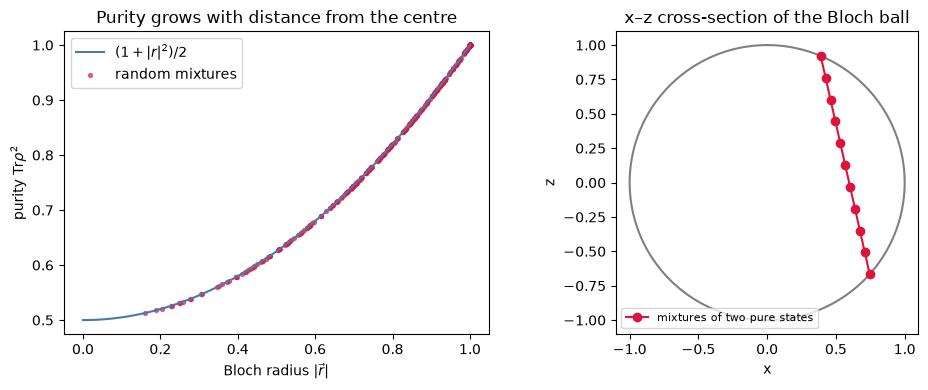

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
rr = np.linspace(0, 1, 100)
ax[0].plot(rr, (1 + rr ** 2) / 2, color="#4c78a8", label=r"$(1+|r|^2)/2$")
ax[0].scatter(radius, pur, s=8, color="crimson", alpha=0.6, label="random mixtures")
ax[0].set_xlabel(r"Bloch radius $|\vec r|$"); ax[0].set_ylabel(r"purity Tr$\rho^2$"); ax[0].legend()
ax[0].set_title("Purity grows with distance from the centre")

t = np.linspace(0, 2 * np.pi, 200)
ax[1].plot(np.sin(t), np.cos(t), color="gray")
a, b = s.bloch(s.dm(s.ket(0.4, 0))), s.bloch(s.dm(s.ket(2.3, 0)))
lam = np.linspace(0, 1, 11)
chord = np.array([s.bloch(l * s.dm(s.ket(0.4, 0)) + (1 - l) * s.dm(s.ket(2.3, 0))) for l in lam])
assert np.allclose(chord, [l * a + (1 - l) * b for l in lam])   # mixing is linear in the Bloch vector
ax[1].plot(chord[:, 0], chord[:, 2], "o-", color="crimson", label="mixtures of two pure states")
ax[1].set_aspect("equal"); ax[1].set_xlabel("x"); ax[1].set_ylabel("z"); ax[1].legend(loc="lower left", fontsize=8)
ax[1].set_title("x–z cross-section of the Bloch ball")
plt.tight_layout(); plt.show()

The 3D view below shows the same random mixtures, coloured by purity. Rotate it and hover over the points. No point leaves the unit ball.

In [8]:
fig = go.Figure([
    go.Surface(x=np.cos(u) * np.sin(v), y=np.sin(u) * np.sin(v), z=np.cos(v), opacity=0.08, showscale=False,
               colorscale=[[0, "gray"], [1, "gray"]], hoverinfo="skip"),
    go.Scatter3d(x=R[:, 0], y=R[:, 1], z=R[:, 2], mode="markers",
                 marker=dict(size=3, color=pur, colorscale="Viridis", cmin=0.5, cmax=1, colorbar=dict(title="purity")),
                 text=[f"|r| = {r:.3f}, purity = {p:.3f}" for r, p in zip(radius, pur)], hoverinfo="text"),
])
fig.update_layout(height=560, title="Random mixed states fill the Bloch ball", margin=dict(l=0, r=0, t=40, b=0),
                  scene=dict(aspectmode="cube"))
show(fig)

## Going deeper

Take a measurement along a unit vector $\hat n$ (observable $\hat n\cdot\vec\sigma$). The Born rule in Bloch form is

$$
P(+1\mid\hat n) = \operatorname{Tr}\!\left[\rho\,\tfrac{1}{2}(I+\hat n\cdot\vec\sigma)\right] = \tfrac{1}{2}\left(1+\vec r\cdot\hat n\right).
$$

So the outcome probability depends only on the projection of the Bloch vector on the measurement axis. Orthogonal states, such as $|0\rangle$ and $|1\rangle$, sit at *antipodal* points on the sphere. They are not perpendicular. The next cell checks the formula for random states and random axes.

In [9]:
g = np.random.default_rng(3)
for _ in range(200):
    rho = random_mixture(2)
    n = g.normal(size=3); n /= np.linalg.norm(n)
    proj = 0.5 * (s.I2 + n[0] * s.X + n[1] * s.Y + n[2] * s.Z)
    assert abs(np.real(np.trace(rho @ proj)) - 0.5 * (1 + s.bloch(rho) @ n)) < 1e-12
# antipodal check: |0> and |1> are orthogonal and have opposite Bloch vectors
assert abs(np.vdot(s.KET0, s.KET1)) == 0 and np.allclose(s.bloch(s.dm(s.KET0)), -s.bloch(s.dm(s.KET1)))
print("Born rule in Bloch form verified for 200 random states and axes.")

Born rule in Bloch form verified for 200 random states and axes.


## Exercises

:::{admonition} Exercise: :label: lab05-ex1
:class: tip
Find the polar angle $\theta$ for which a $Z$ measurement gives outcome 0 with probability $3/4$.
:::

:::{dropdown} Solution
$\cos^2(\theta/2)=3/4$ gives $\cos(\theta/2)=\sqrt3/2$, so $\theta=\pi/3$ (60°). Equivalently $z=\cos\theta = 2p_0-1 = 1/2$. The check cell below verifies it.
:::

:::{admonition} Exercise: :label: lab05-ex2
:class: tip
A qubit has Bloch vector $\vec r=(0.6,0,0)$. Find its purity and its two eigenvalues. Is it pure?
:::

:::{dropdown} Solution
$|\vec r|=0.6$. Purity $=(1+0.36)/2=0.68$. Eigenvalues $(1\pm0.6)/2$, that is $0.8$ and $0.2$. It is mixed, because $|\vec r|<1$.
:::

:::{admonition} Exercise: :label: lab05-ex3
:class: tip
In the worst case $p_0=1/2$, how many shots do you need so that the standard error of $\hat p_0$ is at most $0.01$?
:::

:::{dropdown} Solution
The standard error is $\sqrt{p_0(1-p_0)/N}=0.5/\sqrt N$. Setting $0.5/\sqrt N\le 0.01$ gives $N\ge 2500$.
:::

## Check yourself

In [10]:
# Exercise 1
assert abs(s.qubit(math.pi / 3)["p0"] - 0.75) < 1e-12
assert abs(s.qubit(math.pi / 3)["z"] - 0.5) < 1e-12
# Exercise 2
rho = 0.5 * (s.I2 + 0.6 * s.X)
assert s.is_density_matrix(rho)
assert abs(s.purity(rho) - 0.68) < 1e-12
assert np.allclose(np.sort(np.linalg.eigvalsh(rho)), [0.2, 0.8])
# Exercise 3
N = 2500
assert abs(math.sqrt(0.25 / N) - 0.01) < 1e-15 and math.sqrt(0.25 / (N - 1)) > 0.01
print("All checks passed.")

All checks passed.


## Limits of this model

- This lab covers one qubit only. The Bloch ball is special to a single qubit. Two qubits need 15 real parameters, and the set of two-qubit states is not a ball.
- We assumed ideal measurements: perfect projective measurements with no readout error. Real devices also mislabel outcomes.
- The randomness is simulated. The shots come from a seeded pseudo-random generator. It mimics the statistics of quantum measurement, but it is not quantum randomness.
- The picture ignores the global phase, which no measurement can detect. The relative phase $\varphi$ is physical.